# Wrist X-ray Abnormality Screening: Portfolio Prototype

*A prototype. **Not a diagnostic tool.** Not clinically validated. Never use on real patient data.*

## 1. The problem this project addresses

A wrist radiograph is one of the most routine imaging orders in urgent care, orthopaedic and primary-care settings, and every study has to be read by a trained clinician before the patient gets an answer. In a busy clinic, or one with no radiologist on site, studies wait in arrival order. A displaced fracture can sit behind a dozen normal studies because nobody knows which is which until someone opens it.

Three groups feel that. **Patients** wait, often in pain or in a splint. **Clinicians** spend scarce time reading studies that turn out to be normal and are interrupted while treating others. **Practice managers** own both the throughput problem and the liability: a slow queue hurts the schedule, and a missed or late-caught abnormality is the expensive failure.

Machine learning is being considered for one narrow reason: a model that scores each study for "looks abnormal" could help *reorder* the queue (likely-abnormal first) and, in a stricter use, let clearly-normal studies be fast-tracked for a quick human sign-off. I do not have throughput or cost figures for any real practice, and none are invented here. The question this notebook asks is smaller and testable: **can a model score wrist studies well enough for that to be worth doing, and how will we know when it is not?**

## 2. Why this is worth solving (and why solving it badly is worse than not solving it)

If it works, abnormal studies are read sooner and clinician time goes where it is needed. If it works *badly*, the failure is quiet and the two errors are not symmetric:

- a **false negative** (abnormal study scored "normal") can delay a patient's care if anyone lets that score deprioritise the study;
- a **false positive** (normal study flagged) wastes reading time and, if frequent, teaches staff to ignore the flag;
- an **over-trusted model** is worse than either: a confident-looking probability invites a tired human to stop looking, and a model that is right on one hospital's scanners can be wrong in ways nobody notices on another's.

So this notebook does not chase an accuracy number. It reports recall on the abnormal class, the price paid in precision to raise it, whether the probabilities can be believed, and what the system should refuse to decide.

## 3. What this project does and does not claim

**Does:** train and compare three models (grayscale pixels + logistic regression, HOG features + logistic regression, fine-tuned ResNet18) on the public MURA v1.1 *wrist* subset, with one shared evaluation harness, a patient-level split that is asserted leak-free, a recall-target operating point chosen on validation data, calibration and abstention analysis, and an offline demo app.

**Does not:** diagnose anything; claim clinical validity; generalise beyond one hospital system's images (no external validation); address any regulatory pathway; distinguish *kinds* of abnormality (the label is coarse: normal vs abnormal); or support use on real patient data.

## 4. How to run this notebook

1. From the repository root: `make install` (installs the pinned requirements, including PyTorch) and restart the kernel if the guard cell below complains.
2. Place MURA-v1.1 at `./MURA-v1.1` **or** set the single variable `MURA_ROOT` in the next cell.
3. **Run All.** The notebook is designed to run top-to-bottom with no other edits. If trained models are missing, it trains them (CPU works but ResNet training is slow; `make train-all` beforehand is faster to monitor). Every number shown is computed by the cells below; nothing is typed in.

The code lives in `src/`; this notebook is a narrative over that library and deliberately contains no dataset, transform, model-building or evaluation logic of its own.

In [17]:
MURA_ROOT = None   
%matplotlib inline
import importlib
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / "src" / "config.py").exists():
    raise RuntimeError(f"Cannot find src/config.py under {REPO_ROOT}. Open this notebook from the repository root or from notebooks/.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
if MURA_ROOT is not None:
    os.environ["MURA_ROOT"] = str(MURA_ROOT)     

missing = []
for mod in ["torch", "torchvision", "sklearn", "skimage", "matplotlib", "pandas", "numpy", "PIL", "joblib"]:
    try:
        importlib.import_module(mod)
    except ImportError:
        missing.append(mod)
if missing:
    raise ImportError(f"Missing packages: {missing}. From the repo root run `make install`, then restart this kernel.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from src import (
    calibration,
    compare_models,
    config,
    eval_harness,
    export_onnx,
    mura_utils,
    operating_point,
    train_classical,
    train_resnet,
)

mura_utils.validate_mura_root()   
mura_utils.seed_everything()
device = mura_utils.get_device()
print("MURA_ROOT :", config.MURA_ROOT)
print("torch     :", torch.__version__, "| device:", device)
print(config.DISCLAIMER_SHORT)

[device] WARNING: running on CPU. ResNet18 fine-tuning works on CPU but is much slower than on a GPU. Use `--max-train-images 256 --epochs 1` for a quick plumbing check before committing to a full run.
MURA_ROOT : /home/student/Downloads/mura-wrist-project/MURA-v1.1
torch     : 2.5.1+cpu | device: cpu
Coursework / portfolio prototype. NOT a diagnostic tool. Not clinically validated. Never use on real patient data.


## A1. Problem Definition & Why It Matters

The opening cell stated the problem; this section deepens it with what the *clinical stakes* mean for how the model must be built and judged.

**The task.** Given one wrist radiograph, output the probability that it is **abnormal**. "Abnormal" in MURA is a deliberately coarse label assigned from a radiologist's reading of the study. It bundles acute fractures with things that are not acute at all: surgical hardware, healed injuries, degenerative change, lesions. That matters. A model can be "right" about abnormality while telling a clinician nothing about whether anything needs urgent action, and it can be "wrong" on a study that is abnormal in a way that is clinically uninteresting.

**False negative vs false positive: the asymmetry.** Take the positive class to be *Abnormal*.

- A false negative means an abnormal study is scored as normal. If the score is only used to reorder a queue, the cost is delay. If the score is ever used to *skip* a read, the cost is a missed finding. The harm falls on a patient.
- A false positive means a normal study is flagged. The cost is reading time, and, when false alarms are frequent, alert fatigue: people stop trusting, then stop reading, the flag.

These costs are not equal, and they are not even measured in the same units (patient harm vs staff minutes), which is why a single accuracy figure cannot tell us whether the model is acceptable. As pure arithmetic: if 100 abnormal studies pass through and the model's recall is 0.90, ten are scored as normal. Whether ten is acceptable is a clinical decision, not a statistical one.

**What an over-trusted model costs a practice.** The worst failure is not a wrong prediction; it is a wrong prediction nobody questions.

- *Automation bias:* a precise-looking "93% abnormal / 4% abnormal" lowers the care a human takes.
- *Silent distribution shift:* a model trained at one hospital can degrade on another's equipment and still emit confident numbers.
- *Auto-clear lanes:* any workflow where "leans normal" removes a human read converts every residual miss into an unreviewed miss.
- *Accountability gaps:* when a tool and a clinician disagree, someone has to own the outcome.

**Success criteria, stated before looking at results.** (1) At a recall target of `config.RECALL_TARGET` (0.95 at the time of writing), chosen on the validation split only, the target should also hold on the held-out test split, and the precision cost of reaching it must be reported honestly. (2) The ResNet must beat the simple HOG baseline at that same operating point by enough to justify its cost and opacity; if it does not, the simpler tool wins. (3) The model's uncertain middle must be handed to a human via an abstention band, and the share of abnormal studies that would be wrongly auto-cleared must be reported. Writing these down first protects against redefining success after seeing the numbers.

## A2. Dataset Documentation

**Dataset.** MURA v1.1 (*musculoskeletal radiographs*), Stanford ML Group (Rajpurkar et al., 2017). This project uses only the `XR_WRIST` folders. Studies are stored as `train|valid/XR_WRIST/patientNNNNN/studyK_positive|negative/imageM.png`; the study folder name carries the label (`positive` = abnormal). Labels are therefore **study-level**: every image inherits its study's label, which adds label noise (a view in an abnormal study may show nothing abnormal).

**Terms.** MURA is released for research use after registration; it must not be redistributed (the repository's `.gitignore` excludes it). **Provenance risk:** all images come from one hospital system, so the scanners, positioning habits, patient mix and reporting style are one sample of the world.

The cells below scan the folders on disk and print the real counts. Nothing in this section is typed in.

In [18]:
train_full = mura_utils.build_index(config.MURA_ROOT, config.SPLIT_TRAIN)
valid_full = mura_utils.build_index(config.MURA_ROOT, config.SPLIT_VALID)
official = pd.DataFrame({"official train": mura_utils.class_balance(train_full),
                         "official valid (used as TEST)": mura_utils.class_balance(valid_full)}).T
display(official)

csv_check = mura_utils.compare_with_csv()
if csv_check is None:
    print("Official *_image_paths.csv not found beside the data: completeness check skipped.")
else:
    for split, c in csv_check.items():
        status = "OK" if c["on_disk"] == c["in_csv"] else "MISMATCH (partial download? numbers describe YOUR subset)"
        print(f"{split:5s}: images on disk = {c['on_disk']:>6}, in official CSV = {c['in_csv']:>6}  -> {status}")

,n_images,n_normal,n_abnormal,pct_abnormal,n_studies,n_patients
official train,2604.0,1569.0,1035.0,39.75,908.0,871.0
official valid (used as TEST),659.0,364.0,295.0,44.76,237.0,207.0


Official *_image_paths.csv not found beside the data: completeness check skipped.


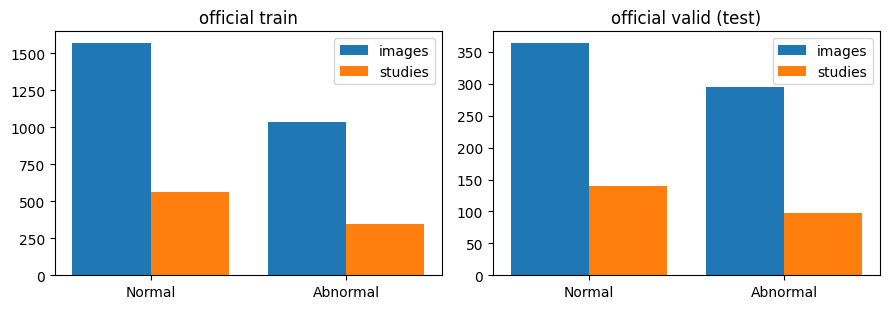

,width,height,aspect_ratio
min,164.0,379.0,0.32
50%,379.0,512.0,0.74
max,512.0,512.0,1.35


Image modes in the sample: {'L': 112, 'RGB': 88}


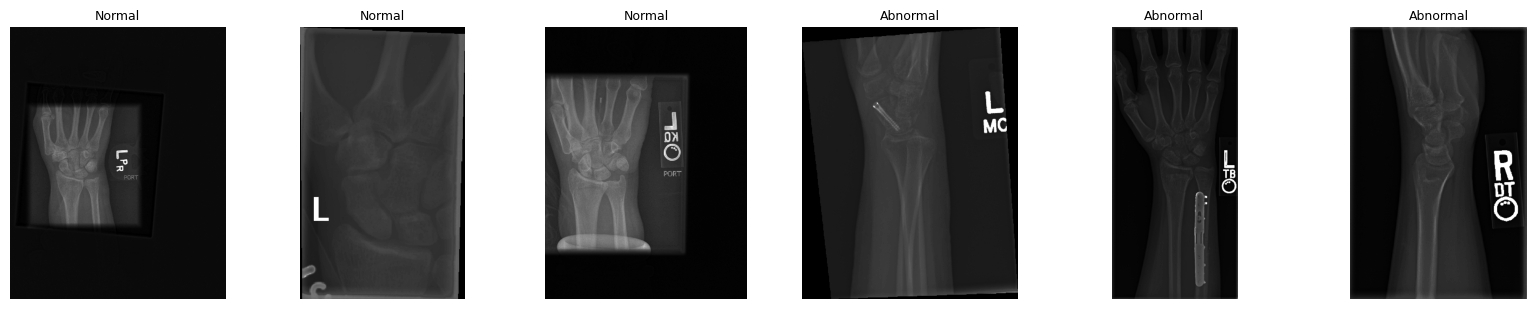

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (name, df) in zip(axes, [("official train", train_full), ("official valid (test)", valid_full)]):
    images = df.label.value_counts().reindex([0, 1], fill_value=0)
    studies = df.drop_duplicates("study_id").label.value_counts().reindex([0, 1], fill_value=0)
    x = np.arange(2)
    ax.bar(x - 0.2, images.values, 0.4, label="images")
    ax.bar(x + 0.2, studies.values, 0.4, label="studies")
    ax.set_xticks(x, list(config.CLASS_NAMES)); ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

props = mura_utils.sample_image_properties(train_full, n=200)
display(props.describe().loc[["min", "50%", "max"]].round(2))
print("Image modes in the sample:", props["mode"].value_counts().to_dict())

examples = pd.concat([train_full[train_full.label == 0].sample(3, random_state=1),
                      train_full[train_full.label == 1].sample(3, random_state=1)])
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, rec in zip(axes, examples.itertuples()):
    ax.imshow(mura_utils.load_pil_image(rec.path), cmap="gray"); ax.axis("off")
    ax.set_title(config.CLASS_NAMES[rec.label], fontsize=9)
plt.tight_layout(); plt.show()

In [20]:
tb, vb = mura_utils.class_balance(train_full), mura_utils.class_balance(valid_full)
display(Markdown(
    f"**What these numbers say (generated from the data above).** The official training split has "
    f"**{tb['n_images']:,} images** from **{tb['n_studies']:,} studies** and **{tb['n_patients']:,} patients**, "
    f"**{tb['pct_abnormal']:.1f}%** of images abnormal. The official validation split, used here as the held-out test set, has "
    f"**{vb['n_images']:,} images** from **{vb['n_patients']:,} patients**, **{vb['pct_abnormal']:.1f}%** abnormal. "
    f"A model that always answered 'Normal' would score an accuracy of "
    f"**{100 - vb['pct_abnormal']:.1f}%** on the test set while catching **0%** of abnormal images, "
    f"which is why accuracy is never reported alone."))

**What these numbers say (generated from the data above).** The official training split has **2,604 images** from **908 studies** and **871 patients**, **39.8%** of images abnormal. The official validation split, used here as the held-out test set, has **659 images** from **207 patients**, **44.8%** abnormal. A model that always answered 'Normal' would score an accuracy of **55.2%** on the test set while catching **0%** of abnormal images, which is why accuracy is never reported alone.

**What the printed numbers mean.**

- **Size.** A few thousand training images is small by deep-learning standards. That is why we start from ImageNet weights rather than from scratch (A4), and why we regularise (augmentation, weight decay, early stopping; A5).
- **Class balance.** The classes are imbalanced rather than extremely skewed. That is enough to make accuracy misleading (the "always normal" figure above is the proof) but not enough to justify aggressive re-weighting; we keep plain binary cross-entropy and judge the model with per-class metrics, AUC and an explicit threshold (A6). Note that image-level and study-level balance differ because studies have different numbers of views.
- **Test-set size.** The test set is small. Every metric computed from it carries sampling uncertainty that we do not quantify with confidence intervals here, so small gaps between models should not be over-read.
- **Completeness check.** If the on-disk counts differ from the official CSVs, every later number describes a subset of MURA, not MURA.
- **Image properties.** Sizes and aspect ratios vary, so images are resized to a fixed square; resizing distorts aspect ratio slightly, which we accept for simplicity and note as a limitation. Images are 8-bit PNG exports, unlike clinical DICOM.
- **Label caveat.** Study-level labels and a heterogeneous "abnormal" class (A1) put a ceiling on what any image-level model can achieve and make "abnormal" a weaker concept than "fracture".

## A3. Data Preparation & Splitting

**Why a patient-level split.** Several images from one patient (and several studies from one patient) are near-duplicates of each other. If some of a patient's images land in training and others in test, the model is partly tested on things it has memorised, and the test score is optimistic in a way that evaporates in deployment. So the unit of splitting is the **patient**, never the image or the study.

**Three splits, three jobs.**

- *Test* = the official MURA `valid` split for wrist. It is never used to fit, to stop training, or to choose a threshold.
- *Validation* = 15% of the official-train **patients** (stratified by whether the patient has any abnormal study). It is used to choose regularisation (classical models), to stop training (ResNet) and to choose the operating threshold.
- *Train* = the remaining official-train patients.

**The leakage assertion.** `mura_utils.assert_no_patient_leakage` raises an error if any patient (or any file) appears in more than one split, and `make_splits` calls it every time. It is written as an explicit `raise` rather than an `assert` statement so it still fires under `python -O`. The cells below run it, print the overlaps explicitly, and then *prove the guard works* by feeding it a deliberately corrupted split.

**Preprocessing.** Images are decoded as 8-bit grayscale, replicated to three channels (the pretrained network expects RGB), resized to 224×224 and normalised with ImageNet mean/std, because the backbone's weights were learned under that normalisation. Using the same statistics at inference is part of the contract (A7).

In [21]:
splits = mura_utils.load_splits()          # scans, splits, and runs the leakage assertion internally
summary = pd.DataFrame(mura_utils.summarize_splits(splits)).T
display(summary)

mura_utils.assert_no_patient_leakage(splits)   # the visible, non-negotiable check
names = list(splits)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        shared = set(splits[a].patient_id) & set(splits[b].patient_id)
        print(f"patients shared by {a:5s} and {b:5s}: {len(shared)}")
print("LEAKAGE CHECK PASSED: no patient appears in more than one split.")

   /home/student/Downloads/mura-wrist-project/MURA-v1.1/train/XR_WRIST/patient03944/study1_positive/image3.png


,n_images,n_normal,n_abnormal,pct_abnormal,n_studies,n_patients
train,2217.0,1341.0,876.0,39.51,771.0,740.0
val,386.0,228.0,158.0,40.93,137.0,131.0
test,659.0,364.0,295.0,44.76,237.0,207.0


patients shared by train and val  : 0
patients shared by train and test : 0
patients shared by val   and test : 0
LEAKAGE CHECK PASSED: no patient appears in more than one split.


In [22]:
corrupted = {k: v.copy() for k, v in splits.items()}
leaked_row = corrupted["train"].iloc[[0]].copy()
leaked_row["path"] = leaked_row["path"] + ".copy"        
corrupted["test"] = pd.concat([corrupted["test"], leaked_row], ignore_index=True)
try:
    mura_utils.assert_no_patient_leakage(corrupted)
    raise RuntimeError("The leakage guard did NOT fire. Do not trust any metric from this pipeline.")
except AssertionError as err:
    print("Guard works. Deliberately corrupted split was rejected:\n ", err)

Guard works. Deliberately corrupted split was rejected:
  PATIENT LEAKAGE between 'train' and 'test': 1 patients appear in both (e.g. ['patient03005']). Do not trust any metric until this is fixed.


## A4. Model Architecture & Justification

**Choice: ImageNet-pretrained ResNet18, final layer replaced by one logit, all layers fine-tuned.**

**Why transfer learning rather than training from scratch.** With only a few thousand training images, a randomly initialised network has to learn edges, textures and shapes *and* the task from very little data, and it overfits. ImageNet-pretrained weights already encode general low-level visual structure (edges, gradients, simple textures) that is useful in radiographs even though the photographs it was learned from look nothing like X-rays. Starting there is the standard, defensible default in small-data medical imaging.

**Why ResNet18 rather than ResNet50.** ResNet50 has more than twice the parameters (compare below) and costs correspondingly more to train and to run, with no evidence here that *capacity* is the limiting factor; with so little data, extra capacity mostly buys extra overfitting. Residual connections make ResNet18 easy to optimise, it is small enough to train on a CPU in a pinch, and its behaviour is well understood. If ResNet18 were clearly underfitting (high training loss), that would be the signal to try a bigger model; we did not run that ablation, and it is listed as future work rather than claimed.

**Why fine-tune the whole network rather than freeze the backbone.** ImageNet features come from colour photographs; radiographs are single-channel with very different intensity statistics and textures. A frozen backbone has to express a bone-specific decision using features that were never trained to see bone. Updating all layers lets later layers adapt. The danger is overfitting and "forgetting" useful features, which is why we use a low learning rate (1e-4), weight decay, mild augmentation and early stopping. A frozen-backbone comparison would be a fair ablation; it was not run here, so this is a reasoned default, not a measured conclusion.

**Why a single logit with a sigmoid.** The task is binary, so one logit with `BCEWithLogitsLoss` is the simplest correct formulation, and the sigmoid output is the probability used for thresholds, calibration and abstention.

**Why also train two simple baselines.** Grayscale-pixels and HOG features with logistic regression are cheap, fast and interpretable. If they come close to the CNN, the CNN's cost and opacity are not justified; if the CNN is far ahead, we have evidence it is earning its keep. The baselines make "do we need deep learning?" an empirical question.

In [23]:
from torchvision import models


def n_params(m):
    return sum(p.numel() for p in m.parameters())

r18 = mura_utils.build_resnet18(pretrained=False)        
r50 = models.resnet50(weights=None)
table = pd.DataFrame({
    "model": ["ResNet18 + 1-logit head (used)", "ResNet50 (considered, not used)"],
    "parameters": [n_params(r18), n_params(r50)],
})
table["relative to ResNet18"] = (table.parameters / table.parameters.iloc[0]).round(2)
display(table)
print("Head of the model we use:", r18.fc)
print("All layers trainable (whole-network fine-tuning):", all(p.requires_grad for p in r18.parameters()))

,model,parameters,relative to ResNet18
0,ResNet18 + 1-logit head (used),11177025,1.00
1,"ResNet50 (considered, not used)",25557032,2.29


Head of the model we use: Linear(in_features=512, out_features=1, bias=True)
All layers trainable (whole-network fine-tuning): True


## A5. Training Process

| Choice | Value | Why |
|---|---|---|
| Loss | `BCEWithLogitsLoss` | Numerically stable fusion of sigmoid and binary cross-entropy for one logit. No `pos_weight`: the classes are only mildly imbalanced, and re-weighting would shift the probabilities we later want to calibrate. |
| Optimiser | Adam, weight decay 1e-4 | Robust default for fine-tuning; weight decay is a cheap regulariser for a small dataset. |
| Learning rate | 1e-4 | Low enough not to destroy pretrained features during whole-network fine-tuning. |
| Batch size | 32 | Fits on a modest GPU or CPU and gives reasonably stable gradients. |
| Epochs | up to 15 | A ceiling; early stopping normally ends training sooner. |
| Early stopping | validation **loss**, patience 3, best checkpoint kept | Validation loss is smoother than accuracy and penalises over-confidence, which is exactly what we want to catch. We reload the best epoch, not the last. |
| Seed | `config.RANDOM_SEED` | Reproducibility within limits; CUDA runs are not guaranteed bitwise-identical. |

**Augmentation (training only), and why each is safe for wrist radiographs.**

- *Horizontal flip (p=0.5).* A flipped wrist radiograph looks like a plausible radiograph of the opposite wrist, so anatomy stays realistic. Caveat: laterality letters in the image become mirrored; flipping may even reduce reliance on them, but it does not eliminate the risk that the model uses such markers as a shortcut.
- *Rotation of at most ±7°.* Patient positioning varies by a few degrees between technologists; this simulates that. Larger rotations create unrealistic views and can mimic different projections.
- *Brightness/contrast jitter of ±10%.* Exposure and detector differences change overall density. The range is deliberately small, because subtle density changes *are* the signal for some pathology.

**Deliberately excluded.** Vertical flips (anatomically implausible orientation), large rotations or perspective warps (unrealistic views), random crops or random erasing (can remove the abnormal region while leaving the label as "abnormal", creating label noise), aggressive gamma or histogram manipulation (can erase thin fracture lines), and elastic deformation (changes bone shape). The evaluation transform applies none of the augmentation, only the shared deterministic preprocessing.

TRAIN transform : ['Grayscale', 'Resize', 'RandomHorizontalFlip', 'RandomRotation', 'ColorJitter', 'ToTensor', 'Normalize']
EVAL  transform : [('Grayscale', 3), ('Resize', (224, 224)), ('ToTensor',), ('Normalize', (0.485, 0.456, 0.406), (0.229, 0.224, 0.225))]


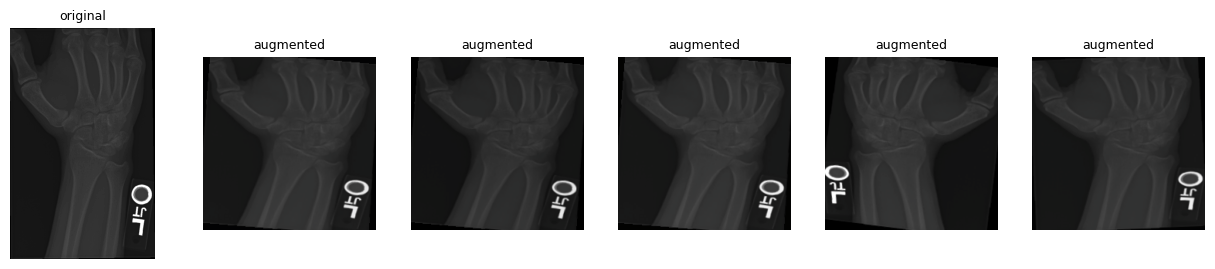

In [24]:
print("TRAIN transform :", [s[0] for s in config.describe_transform(config.get_train_transform())])
print("EVAL  transform :", config.describe_transform(config.get_eval_transform()))
sample_path = splits["train"].path.iloc[0]
fig = eval_harness.plot_augmentations(sample_path, n=5)
display(fig)

[reuse] classical baselines: found ['classical_metrics.json', 'mura_grayscale_logistic.joblib', 'mura_hog_logistic.joblib']
[reuse] ResNet18: found ['resnet_metrics.json', 'resnet18_wrist.pt']


,train_loss,val_loss,train_acc,val_acc,val_auc
epoch,,,,,
1,0.5283,0.4552,0.7388,0.8005,0.8689
2,0.3727,0.4634,0.8300,0.8135,0.8739
3,0.3207,0.6307,0.8570,0.7979,0.8323
4,0.2547,0.5104,0.8972,0.7850,0.8696


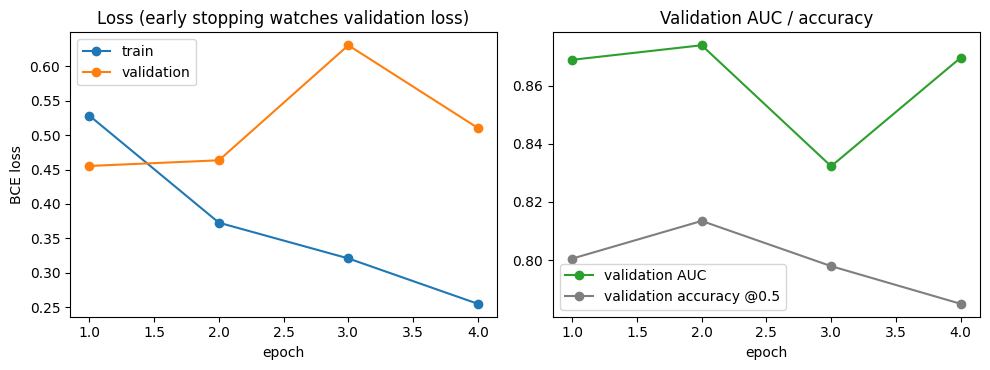

Epochs run: 4 (best epoch 1), train time 536s on cpu


In [25]:
def ensure(paths, runner, label):
    if all(Path(p).exists() for p in paths):
        print(f"[reuse] {label}: found {[Path(p).name for p in paths]}")
        return
    print(f"[run] {label}: artifacts not found, training now ...")
    if runner([]) != 0:
        raise RuntimeError(f"Training {label} failed; see the error above.")

ensure([config.CLASSICAL_METRICS_JSON, config.GRAYSCALE_MODEL_PATH, config.HOG_MODEL_PATH], train_classical.main, "classical baselines")
ensure([config.RESNET_METRICS_JSON, config.RESNET_CKPT_PATH], train_resnet.main, "ResNet18")

classical = eval_harness.read_json(config.CLASSICAL_METRICS_JSON, "make train-classical")
resnet_report = eval_harness.read_json(config.RESNET_METRICS_JSON, "make train-resnet")
if classical.get("smoke_test") or resnet_report.get("smoke_test"):
    raise RuntimeError("Saved artifacts come from a --max-train-images smoke test and are NOT meaningful. Delete outputs/ and models/ contents (make clean) and re-run training.")

history = resnet_report["history"]
display(pd.DataFrame(history, index=range(1, len(history["train_loss"]) + 1)).rename_axis("epoch").round(4))
display(train_resnet.plot_training_curve(history))
print(f"Epochs run: {resnet_report['epochs_run']} (best epoch {resnet_report['best_epoch']}), "
      f"train time {resnet_report['train_time_s']:.0f}s on {resnet_report['device']}")

**How to read the training curves.** Look at three things. (1) *Do training and validation loss fall together early on?* That means the model is learning something that generalises to unseen patients. (2) *Does validation loss turn upward while training loss keeps falling?* That is overfitting, and the epoch where validation loss bottoms out is the checkpoint we keep. (3) *Does validation AUC keep improving after validation loss stops improving?* If so, loss and ranking quality are disagreeing, a reminder that no single curve tells the whole story. If the two losses never separate at all and validation AUC sits near 0.5, the model has learned nothing and the right response is to debug the pipeline, not to tune hyperparameters.

## A6. Evaluation

All three models are evaluated by the **same function**, `eval_harness.run_eval`, on the **same held-out test set**. The comparison table below is generated from the saved metrics, not typed.

Reading guide: *Recall* is the share of truly abnormal images caught (1 − recall is the miss rate); *precision* is the share of flagged images that are truly abnormal (the cost side); *AUC* is threshold-free ranking quality; *specificity* is the share of normal images left alone. The default threshold of 0.5 is arbitrary and is revisited below.

# Model comparison (test set)

| Model | Accuracy | Precision (Abn.) | Recall (Abn.) | F1 (Abn.) | AUC | Train time (s) | Inference (ms/img) | Interpretable |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| Grayscale pixels + logistic regression | 0.548 | 0.495 | 0.498 | 0.497 | 0.570 | 122 | 6.6 | Yes (one coefficient per pixel) |
| HOG features + logistic regression | 0.683 | 0.657 | 0.610 | 0.633 | 0.710 | 9 | 4.9 | Partly (one coefficient per HOG cell/orientation) |
| ResNet18 (ImageNet transfer learning) | 0.765 | 0.898 | 0.536 | 0.671 | 0.847 | 536 | 22.3 | No (post-hoc saliency only) |

Test set = official MURA `valid` wrist studies (never used for fitting or model selection). Threshold 0.5; positive class = Abnormal. Train time includes feature extraction (classical) or all epochs (ResNet). Inference = mean single-image latency, file read to probability, on this machine.

*Coursework / portfolio prototype. NOT a diagnostic tool.*

Wrote /home/student/Downloads/mura-wrist-project

,model,accuracy,precision,recall,f1,auc,specificity,train_time_s,inference_ms,interpretable
0,Grayscale pixels + logistic regression,0.548,0.495,0.498,0.497,0.570,0.588,121.798,6.609,Yes (one coefficient per pixel)
1,HOG features + logistic regression,0.683,0.657,0.610,0.633,0.710,0.742,8.705,4.923,Partly (one coefficient per HOG cell/orientation)
2,ResNet18 (ImageNet transfer learning),0.765,0.898,0.536,0.671,0.847,0.951,535.973,22.338,No (post-hoc saliency only)


,model,class,precision,recall,f1,support
0,Grayscale pixels + logistic regression,Normal,0.591,0.588,0.590,364
1,Grayscale pixels + logistic regression,Abnormal,0.495,0.498,0.497,295
2,HOG features + logistic regression,Normal,0.701,0.742,0.721,364
3,HOG features + logistic regression,Abnormal,0.657,0.610,0.633,295
4,ResNet18 (ImageNet transfer learning),Normal,0.716,0.951,0.817,364
5,ResNet18 (ImageNet transfer learning),Abnormal,0.898,0.536,0.671,295


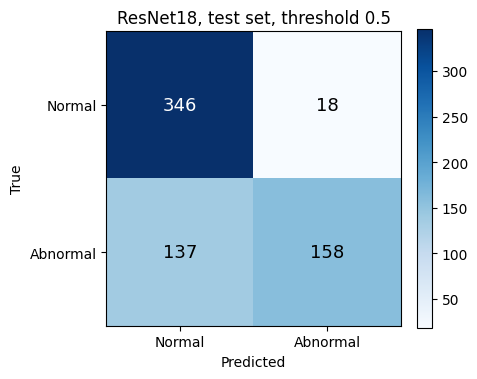

ResNet18 @0.5: 137 abnormal images missed (FN), 18 normal images flagged (FP), 158 caught (TP), 346 cleared (TN).


In [26]:
compare_models.main([])                         
comparison = compare_models.build_comparison()
display(comparison.drop(columns=["model_key"]).round(3))

reports = {"grayscale": classical["grayscale"], "hog": classical["hog"], "resnet": resnet_report}
per_class = []
for key, rep in reports.items():
    for cls, m in rep["test"]["per_class"].items():
        per_class.append({"model": config.MODEL_DISPLAY_NAMES[key], "class": cls, **m})
display(pd.DataFrame(per_class).round(3))

cm = reports["resnet"]["test"]["confusion_matrix"]
display(eval_harness.plot_confusion_matrix(cm, "ResNet18, test set, threshold 0.5"))
tn, fp, fn, tp = np.ravel(cm)
print(f"ResNet18 @0.5: {fn} abnormal images missed (FN), {fp} normal images flagged (FP), {tp} caught (TP), {tn} cleared (TN).")

**Recall-target operating point.** The default 0.5 threshold is not a clinical decision. If a missed abnormality is the expensive error, we should instead pick the highest threshold that reaches a target recall, **choosing it on the validation split only**, then freeze it and apply it to the test split. We report whether the target was actually met on test (selection on validation does not guarantee it transfers), and what it cost in precision, specificity and the share of images flagged. The same analysis is run for the HOG baseline so the comparison is at equal recall, which is the only fair way to compare a screening-style model.

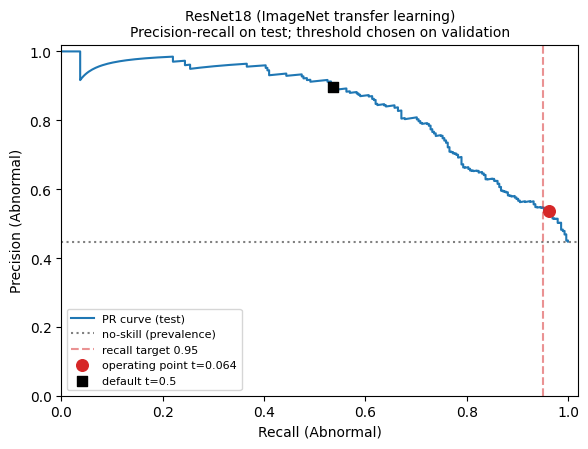

,model,operating point,recall,precision,specificity,flagged share
0,ResNet18,default 0.5,0.536,0.898,0.951,0.267
1,ResNet18,recall target (t=0.064),0.963,0.536,0.324,0.804
2,HOG + logistic,default 0.5,0.610,0.657,0.742,0.416
3,HOG + logistic,recall target (t=0.285),0.868,0.507,0.316,0.766


Recall target 0.95 met on the TEST set by ResNet18: True; precision cost vs 0.5: 0.362; extra share of images flagged: 53.7%


In [27]:
op, fig = operating_point.run("resnet")
display(fig)
op_hog, _ = operating_point.run("hog")
rows = []
for name, rep in [("ResNet18", op), ("HOG + logistic", op_hog)]:
    for label, block in [("default 0.5", rep["test_at_default_0.5"]), (f"recall target (t={rep['threshold']:.3f})", rep["test_at_threshold"])]:
        rows.append({"model": name, "operating point": label, "recall": block["recall"], "precision": block["precision"],
                     "specificity": block["specificity"], "flagged share": block["flagged_fraction"]})
display(pd.DataFrame(rows).round(3))
print(f"Recall target {op['recall_target']} met on the TEST set by ResNet18: {op['target_met_on_test']}; "
      f"precision cost vs 0.5: {op['precision_cost']:.3f}; extra share of images flagged: {op['extra_flagged_fraction']:.1%}")

**Calibration and abstention.** A model that says "0.9" should be right about 90% of the time when it says so; otherwise the number invites over-trust. The reliability diagram compares predicted probability with the observed share of abnormal images per bin, and the Expected Calibration Error (ECE) summarises the gap. The **abstention band** then turns uncertainty into policy: scores below the validation-derived recall-target threshold are "leans normal" (candidates for fast sign-off, never automatic discharge), scores at or above `config.ABSTAIN_HIGH` are "leans abnormal", and everything in between is handed to a human. We report how much work that hands back (fraction abstained) and how well the model does on what it *does* decide, including how many abnormal images would be wrongly auto-cleared.

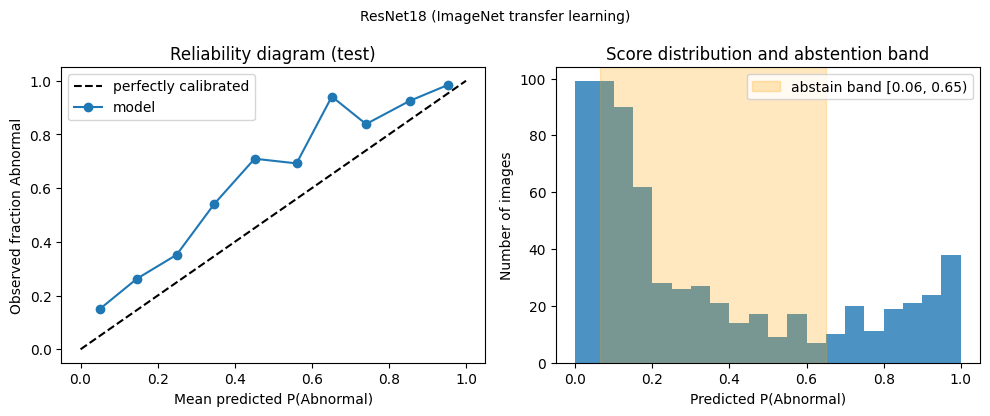

,"ResNet18, test set"
ECE,0.116
Brier score,0.167
band low (recall-target threshold),0.064
band high,0.650
fraction of test images abstained,0.587
auto-decided accuracy,0.923
auto-decided recall (abnormal),0.924
auto-decided precision (abnormal),0.930
abnormal rate among auto-cleared images,0.085
share of ALL abnormal images auto-cleared,0.037


In [28]:
cal, fig = calibration.run("resnet")
display(fig)
ab = cal["abstention"]; m = ab["auto_decided_metrics"]
display(pd.Series({
    "ECE": cal["ece"], "Brier score": cal["brier"],
    "band low (recall-target threshold)": ab["low"], "band high": ab["high"],
    "fraction of test images abstained": ab["fraction_abstained"],
    "auto-decided accuracy": m["accuracy"], "auto-decided recall (abnormal)": m["recall_abnormal"],
    "auto-decided precision (abnormal)": m["precision_abnormal"],
    "abnormal rate among auto-cleared images": ab["auto_clear_miss_rate"],
    "share of ALL abnormal images auto-cleared": ab["abnormal_auto_cleared_fraction"],
    "share of ALL abnormal images sent to a human": ab["abnormal_sent_to_human_fraction"],
}, name="ResNet18, test set").round(3).to_frame())

**Error analysis.** Aggregate metrics say *how often* the model is wrong; they do not say *why*. Below we look at the most **confident** mistakes of each kind (false negatives the model was sure were normal, false positives it was sure were abnormal), because those are where over-trust would hurt. Look at the images before reading any table and write down what they have in common.

Then we test a specific, named failure-mode hypothesis instead of telling a story. **Hypothesis H1: images with metal hardware (plates, screws, wires) are over-flagged as abnormal.** In MURA, "abnormal" includes post-operative hardware, which is not an acute finding; a model might learn "bright metal" as a shortcut for "abnormal". There is no hardware label in the data, so we use a crude proxy: the fraction of near-saturated pixels (metal is radio-opaque and renders very bright). The proxy is imperfect (markers, collimation edges and exposure also create bright pixels), so a result here is a hypothesis check, not a finding. The verdict below is computed, not asserted, and a hypothesis the data does not support is reported as such.

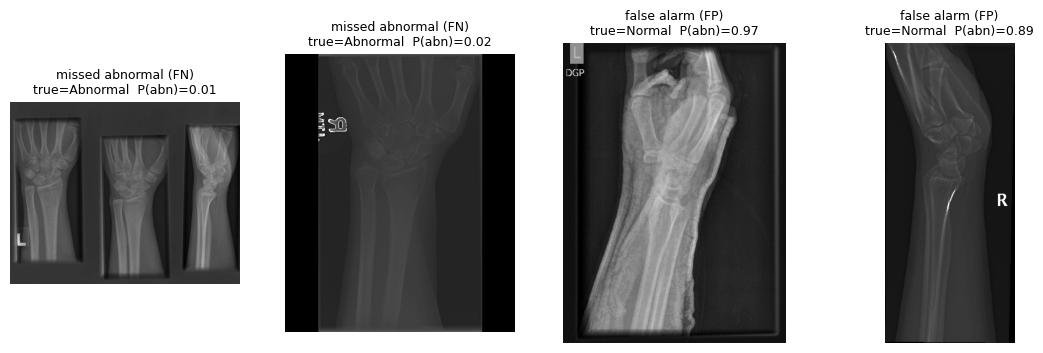

,file,kind,label,prob
0,patient11278/study1_positive/image1.png,FN,1,0.007
1,patient11252/study1_positive/image2.png,FN,1,0.020
2,patient11326/study1_negative/image2.png,FP,0,0.970
3,patient11380/study1_negative/image2.png,FP,0,0.890


In [29]:
test_pred = eval_harness.load_predictions("resnet", "test")
errors = eval_harness.select_error_examples(test_pred["paths"], test_pred["labels"], test_pred["probs"], threshold=0.5, k_fn=2, k_fp=2)
display(eval_harness.plot_error_examples(errors))
display(errors.assign(file=errors.path.map(lambda p: "/".join(Path(p).parts[-3:])))[["file", "kind", "label", "prob"]].round(3))

In [30]:
quart = eval_harness.error_rates_by_bright_quartile(test_pred["paths"], test_pred["labels"], test_pred["probs"], threshold=0.5)
display(quart.round(3))

fp_top = quart.false_positive_rate.iloc[3]
fp_rest = quart.false_positive_rate.iloc[:3].mean()
gap = fp_top - fp_rest
if np.isnan(gap):
    verdict = "could not be evaluated (a quartile has no normal images)."
elif gap > 0.10:
    verdict = (f"**supported as a lead worth investigating**: the false-positive rate in the brightest quartile is {fp_top:.1%} "
               f"versus {fp_rest:.1%} in the other quartiles. This is consistent with hardware-like bright structures being flagged, "
               f"but the proxy is crude and the sample is small; confirm by having a clinician review the flagged normal images.")
else:
    verdict = (f"**not supported by this proxy**: the false-positive rate in the brightest quartile ({fp_top:.1%}) is not clearly higher "
               f"than in the other quartiles ({fp_rest:.1%}). Either hardware is not the main driver of false alarms, or this proxy cannot see it. "
               f"The failure mode needs another look at the displayed images, not a story.")
display(Markdown(f"**H1 (bright, hardware-like images are over-flagged) {verdict}**  \n"
                 f"The 0.10 gap rule is an informal screening threshold, not a statistical test."))

,quartile,n_images,median_bright_fraction,false_positive_rate,false_negative_rate
0,Q1 (fewest bright px),165,0.000,0.024,0.605
1,Q2,165,0.000,0.050,0.492
2,Q3,164,0.001,0.028,0.579
3,Q4 (most bright px),165,0.008,0.110,0.250


**H1 (bright, hardware-like images are over-flagged) **not supported by this proxy**: the false-positive rate in the brightest quartile (11.0%) is not clearly higher than in the other quartiles (3.4%). Either hardware is not the main driver of false alarms, or this proxy cannot see it. The failure mode needs another look at the displayed images, not a story.**  
The 0.10 gap rule is an informal screening threshold, not a statistical test.

**What to take from the error analysis.** First, whichever way H1 came out, the point of this step is the *method*: name a specific, falsifiable failure mode, find a measurable proxy, and report the result even when it does not flatter the model. Second, the displayed mistakes are the cases to bring to a clinician: ask whether they are genuinely ambiguous (in which case the abstention band should catch them), label-noise artefacts (an abnormal study whose displayed view shows nothing), or real systematic errors (in which case the fix is data and labels, not tuning). Third, a confident false negative is the worst finding in this notebook: if the abstention band does not catch it, "leans normal" must never remove a human read.

## A7. Model Export

**What is saved.** `models/resnet18_wrist.pt` holds the `state_dict` (weights only, loaded with `weights_only=True` so that loading cannot execute arbitrary code) together with a small metadata block recording the preprocessing contract. Saving *weights* rather than a pickled model object keeps the file safe to load and independent of this code's class layout.

**ONNX (optional).** Exporting to ONNX makes the model runnable without PyTorch. It is only trusted after a **parity check**: PyTorch and ONNX Runtime must agree on the same inputs within a small tolerance, otherwise the export script fails loudly. Install the optional dependencies with `make install-onnx`.

**The preprocessing contract (what `app.py` must reproduce exactly).**

1. Decode the image to 8-bit grayscale (`mura_utils.load_pil_image`).
2. Replicate to 3 channels.
3. Resize to 224 × 224.
4. Convert to a tensor in [0, 1].
5. Normalise with ImageNet mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225).
6. The network returns one logit; P(abnormal) = sigmoid(logit).

All six steps come from one object, `config.get_eval_transform()`. `app.py` uses the same object and asserts at startup that it still matches this sequence; the cells below demonstrate the contract and check that a file read from disk and the same bytes "uploaded" through the browser path give bit-identical tensors.

In [31]:
from io import BytesIO

model, meta = mura_utils.load_resnet_checkpoint(config.RESNET_CKPT_PATH)
n_tensors = sum(1 for _ in model.state_dict())
print(f"Checkpoint {config.RESNET_CKPT_PATH.name}: {n_tensors} tensors; best epoch {meta.get('best_epoch')}, val loss {meta.get('val_loss'):.4f}")

contract = export_onnx.build_contract()
print("Preprocessing contract:")
for step in contract["preprocessing_steps"]:
    print("  ", step)

p = Path(test_pred["paths"][0])
tf = config.get_eval_transform()
from_disk = tf(mura_utils.load_pil_image(p))
from_upload = tf(mura_utils.load_pil_image(BytesIO(p.read_bytes())))
assert torch.equal(from_disk, from_upload), "Upload path and disk path give different tensors: app/eval parity is broken."
print("Disk-vs-upload preprocessing parity: PASSED (bit-identical tensors).")

try:
    onnx_report = export_onnx.export()
    print("ONNX export + parity check passed. max |torch - onnx| =", onnx_report["parity_max_abs_diff"])
except ImportError as err:
    print("ONNX step skipped (optional):", err)

Checkpoint resnet18_wrist.pt: 122 tensors; best epoch 1, val loss 0.4552
Preprocessing contract:
   ['Grayscale', 3]
   ['Resize', [224, 224]]
   ['ToTensor']
   ['Normalize', [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]]
Disk-vs-upload preprocessing parity: PASSED (bit-identical tensors).
ONNX step skipped (optional): ONNX export needs `onnx` and `onnxruntime`. Run: make install-onnx


## A8. Limitations, Ethics & What Real Clinical Deployment Would Require

**Limitations of this work (each one caps how far the results can be trusted).**

- **Single-site data, no external validation.** Train, validation and test all come from one hospital system's images. The split is patient-disjoint but not site-disjoint, so the test score estimates performance on *similar* patients and scanners, not on yours.
- **Coarse, noisy label.** "Abnormal" mixes fractures, hardware, degenerative change and more, and each image inherits its study's label. The model learns a blurry concept; it is not a fracture detector.
- **Image-level, not study-level.** A clinical read integrates several views. Aggregating view-level scores into a study-level decision was not evaluated.
- **Small test set, no confidence intervals.** Differences between models can be within sampling noise. A patient-level bootstrap would be the next step.
- **No subgroup analysis.** The data carries no demographic metadata, so unequal performance by age, sex or ethnicity cannot be measured, and its absence is not evidence of fairness.
- **Possible shortcut learning.** The model may use acquisition artefacts, laterality markers or hardware rather than pathology. A1/A6 test one hypothesis; others remain open.
- **Calibration is imperfect** (see the reliability diagram), so probabilities are scores, not guaranteed chances.
- **Preprocessing choices** (square resize, 8-bit PNG input) were not compared against alternatives.

**Ethics.** The central risks are automation bias and false reassurance. The demo therefore always shows an "inconclusive" state and an unmissable not-a-diagnosis banner, runs offline, and stores nothing it is shown. MURA must be used under its research terms and never combined with real patient data; no re-identification should be attempted.

**What real clinical deployment would require.** None of this has been done here.

1. **External, multi-site validation** on local images, with the results (including failures) written down.
2. **Clinician-defined success criteria** and an agreed operating point, with the cost of false alarms and misses decided by clinical leadership.
3. **Prospective, human-factors-aware evaluation**: do clinicians read better, faster or *worse* with the score? Measure behaviour, not just model metrics.
4. **Regulatory assessment** of the software as a medical device in the relevant jurisdiction, quality management, and documented change control.
5. **Privacy and security review** (for example GDPR or HIPAA, depending on where it runs), access control, audit logging, and approved infrastructure for any real images.
6. **Study-level aggregation, uncertainty quantification and subgroup analysis.**
7. **Ongoing monitoring**: drift in score distributions, clinician override rates, and review of every missed abnormality (see `docs/DECISION.md`).
8. **A named owner** accountable for the system after launch, and a switch that turns it off.

**Next steps if this were continued:** frozen-backbone and ResNet50 ablations, a patient-level bootstrap for confidence intervals, study-level aggregation, saliency maps used *sceptically* (they can look convincing without being faithful), and a reader study with clinicians.

In [32]:
import json

nb_path = REPO_ROOT / "notebooks" / "MURA_Wrist_Classification.ipynb"
markers = ["{" + "{", "<" + "<"]
if not nb_path.exists():
    raise FileNotFoundError(f"Notebook file not found at {nb_path}; cannot scan it.")
nb = json.loads(nb_path.read_text(encoding="utf-8"))
hits = []
for i, cell in enumerate(nb["cells"]):
    text = "".join(cell.get("source", []))
    for mk in markers:
        if mk in text:
            hits.append((i, cell["cell_type"], mk))
if hits:
    raise RuntimeError(f"Leftover placeholder tokens found in notebook cells: {hits}")
print(f"Token scan complete: 0 leftover placeholder tokens in {len(nb['cells'])} cells.")
print("Also run after execution:  python scripts/check_notebook_tokens.py notebooks/MURA_Wrist_Classification.ipynb  (scans outputs too)")

Token scan complete: 0 leftover placeholder tokens in 31 cells.
Also run after execution:  python scripts/check_notebook_tokens.py notebooks/MURA_Wrist_Classification.ipynb  (scans outputs too)
